# VELV analysis in R3

This notebook explores `VELVETFRUIT_EXTRACT` in round 3. Day 2 is held out and excluded here so it remains available for backtest validation later.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def find_data_dir() -> Path:
    for candidate in (Path('R3/Data'), Path('../Data'), Path('Data')):
        if candidate.exists():
            return candidate
    raise FileNotFoundError('Could not find R3/Data from the current notebook location.')

DATA_DIR = find_data_dir()
HOLDOUT_DAY = 2
PRODUCT = 'VELVETFRUIT_EXTRACT'

price_files = [path for path in sorted(DATA_DIR.glob('prices_round_3_day_*.csv')) if int(path.stem.split('_day_')[-1]) != HOLDOUT_DAY]
trade_files = [path for path in sorted(DATA_DIR.glob('trades_round_3_day_*.csv')) if int(path.stem.split('_day_')[-1]) != HOLDOUT_DAY]

prices = pd.concat([pd.read_csv(path, sep=';') for path in price_files], ignore_index=True)
trades = pd.concat([pd.read_csv(path, sep=';').assign(day=int(path.stem.split('_day_')[-1])) for path in trade_files], ignore_index=True)

symbol_prices = prices.loc[prices['product'] == PRODUCT].copy()
symbol_trades = trades.loc[trades['symbol'] == PRODUCT].copy()

print('Data dir:', DATA_DIR)
print('Price rows:', len(prices), 'Trade rows:', len(trades))
print('Products:', sorted(prices['product'].unique().tolist()))
print('Trade symbols:', sorted(trades['symbol'].unique().tolist()))
print('VELV price rows:', len(symbol_prices))
print('VELV trade rows:', len(symbol_trades))
display(symbol_prices.head())
display(symbol_trades.head())

Data dir: ../Data
Price rows: 240000 Trade rows: 2715
Products: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Trade symbols: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
VELV price rows: 20000
VELV trade rows: 895


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
5,0,0,VELVETFRUIT_EXTRACT,5247,67,NaN,NaN,NaN,NaN,5253,67,NaN,NaN,NaN,NaN,5250.0,0.0
13,0,100,VELVETFRUIT_EXTRACT,5248,69,NaN,NaN,NaN,NaN,5253,23,5254.0,46.0,NaN,NaN,5250.5,0.0
25,0,200,VELVETFRUIT_EXTRACT,5248,20,5247.0,40.0,NaN,NaN,5253,60,NaN,NaN,NaN,NaN,5250.5,0.0
47,0,300,VELVETFRUIT_EXTRACT,5248,24,5247.0,40.0,NaN,NaN,5253,64,NaN,NaN,NaN,NaN,5250.5,0.0
55,0,400,VELVETFRUIT_EXTRACT,5248,25,5247.0,37.0,NaN,NaN,5253,62,NaN,NaN,NaN,NaN,5250.5,0.0


,timestamp,buyer,seller,symbol,currency,price,quantity,day
0,2500,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5250.0,4,0
5,5200,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5236.0,3,0
6,5500,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5241.0,8,0
9,9300,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5229.0,6,0
12,11900,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5237.0,4,0


In [2]:
symbol_prices = symbol_prices.sort_values(['day', 'timestamp']).reset_index(drop=True)
symbol_trades = symbol_trades.sort_values(['day', 'timestamp']).reset_index(drop=True)

book = symbol_prices.assign(
    spread=symbol_prices['ask_price_1'] - symbol_prices['bid_price_1'],
    imbalance=(symbol_prices['bid_volume_1'] - symbol_prices['ask_volume_1']) / (symbol_prices['bid_volume_1'] + symbol_prices['ask_volume_1']),
    microprice=(symbol_prices['ask_price_1'] * symbol_prices['bid_volume_1'] + symbol_prices['bid_price_1'] * symbol_prices['ask_volume_1']) / (symbol_prices['bid_volume_1'] + symbol_prices['ask_volume_1']),
)
book['mid_change'] = book.groupby('day')['mid_price'].diff()
book['pct_change'] = book.groupby('day')['mid_price'].pct_change()
book['next_mid_change'] = book.groupby('day')['mid_price'].shift(-1) - book['mid_price']

trade_mid = symbol_trades.merge(
    book[['day', 'timestamp', 'mid_price', 'spread', 'imbalance', 'microprice']],
    on=['day', 'timestamp'],
    how='left',
)
trade_mid['edge_vs_mid'] = trade_mid['price'] - trade_mid['mid_price']
trade_mid['notional'] = trade_mid['price'] * trade_mid['quantity']

daily_summary = book.groupby('day').agg(
    observations=('timestamp', 'size'),
    start_mid=('mid_price', 'first'),
    end_mid=('mid_price', 'last'),
    low_mid=('mid_price', 'min'),
    high_mid=('mid_price', 'max'),
    mean_mid=('mid_price', 'mean'),
    median_mid=('mid_price', 'median'),
    std_mid=('mid_price', 'std'),
    avg_spread=('spread', 'mean'),
    p90_spread=('spread', lambda s: s.quantile(0.9)),
    avg_imbalance=('imbalance', 'mean'),
)
daily_summary['mid_change'] = daily_summary['end_mid'] - daily_summary['start_mid']

trade_summary = trade_mid.groupby('day').agg(
    trades=('timestamp', 'size'),
    qty=('quantity', 'sum'),
    notional=('notional', 'sum'),
)
trade_summary['vwap'] = trade_summary['notional'] / trade_summary['qty']

print('VELV feature snapshot:')
display(book[['mid_price', 'spread', 'imbalance', 'microprice']].describe().T)
print('VELV daily summary:')
display(daily_summary)
print('VELV trade summary:')
display(trade_summary)
print('First few matched trades:')
display(trade_mid[['day', 'timestamp', 'price', 'mid_price', 'edge_vs_mid', 'quantity']].head())

VELV feature snapshot:


,count,mean,std,min,25%,50%,75%,max
mid_price,20000.0,5247.451075,14.184710,5198.00000,5237.500000,5246.500000,5257.500000,5284.500000
spread,20000.0,4.989050,0.844432,1.00000,5.000000,5.000000,5.000000,6.000000
imbalance,20000.0,0.001039,0.395119,-0.96875,-0.431818,0.000000,0.432432,0.971429
microprice,20000.0,5247.443364,14.196979,5198.00000,5237.500000,5246.621939,5257.500000,5285.910256


VELV daily summary:


,observations,start_mid,end_mid,low_mid,high_mid,mean_mid,median_mid,std_mid,avg_spread,p90_spread,avg_imbalance,mid_change
day,,,,,,,,,,,,
0,10000,5250.0,5244.0,5216.5,5284.5,5246.51025,5244.5,13.677795,4.9935,6.0,0.000694,-6.0
1,10000,5245.0,5265.5,5198.0,5283.0,5248.39190,5248.5,14.614362,4.9846,6.0,0.001385,20.5


VELV trade summary:


,trades,qty,notional,vwap
day,,,,
0,445,2689,14107003.0,5246.189290
1,450,2685,14088077.0,5246.956052


First few matched trades:


,day,timestamp,price,mid_price,edge_vs_mid,quantity
0,0,2500,5250.0,5247.5,2.5,4
1,0,5200,5236.0,5238.5,-2.5,3
2,0,5500,5241.0,5238.5,2.5,8
3,0,9300,5229.0,5230.0,-1.0,6
4,0,11900,5237.0,5234.5,2.5,4


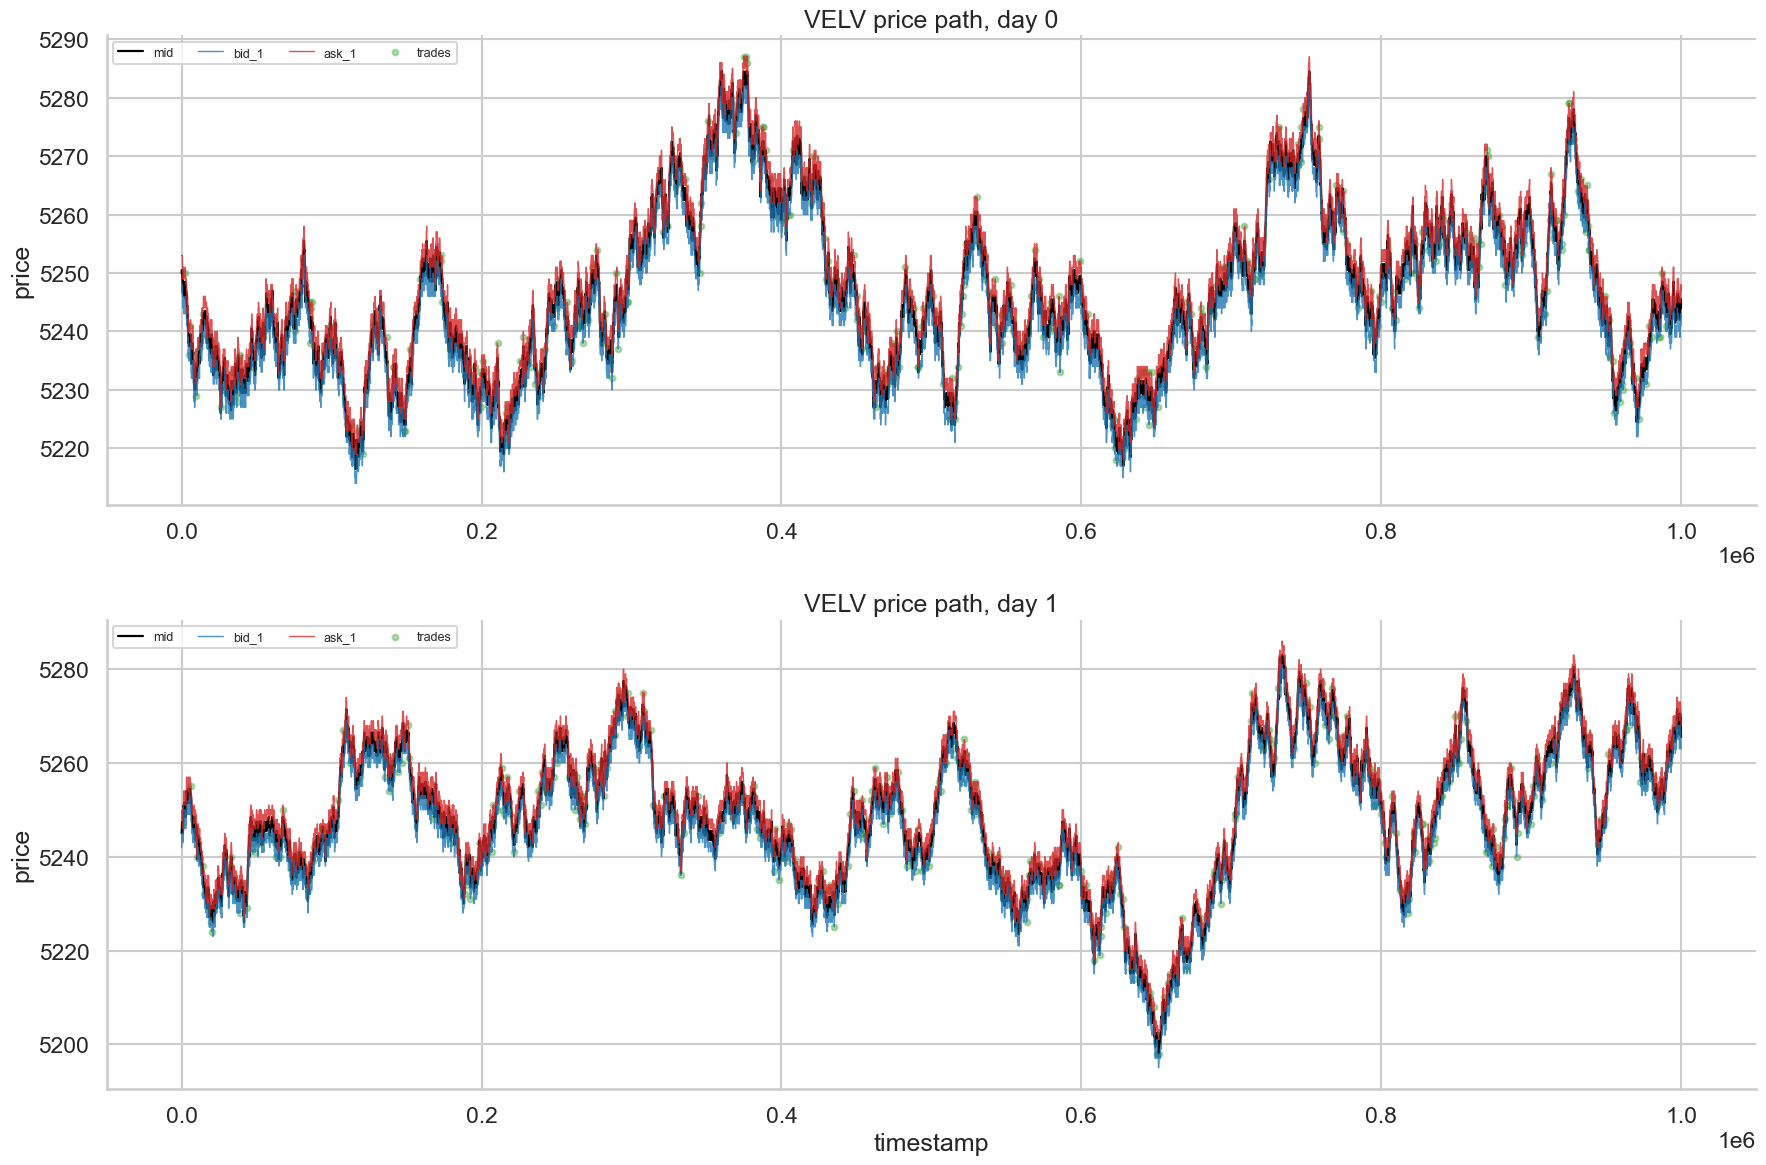

In [3]:
days = sorted(book['day'].unique().tolist())
fig, axes = plt.subplots(len(days), 1, figsize=(18, 12), sharex=False)

for ax, day in zip(axes, days):
    day_prices = book.loc[book['day'] == day]
    day_trades = trade_mid.loc[trade_mid['day'] == day]

    ax.plot(day_prices['timestamp'], day_prices['mid_price'], color='black', lw=1.6, label='mid')
    ax.plot(day_prices['timestamp'], day_prices['bid_price_1'], color='#1f77b4', lw=1.0, alpha=0.8, label='bid_1')
    ax.plot(day_prices['timestamp'], day_prices['ask_price_1'], color='#d62728', lw=1.0, alpha=0.8, label='ask_1')
    ax.scatter(day_trades['timestamp'], day_trades['price'], s=18, color='#2ca02c', alpha=0.35, label='trades')
    ax.set_title(f'VELV price path, day {day}')
    ax.set_ylabel('price')
    ax.legend(loc='upper left', ncol=4, fontsize=9)

axes[-1].set_xlabel('timestamp')
plt.tight_layout()

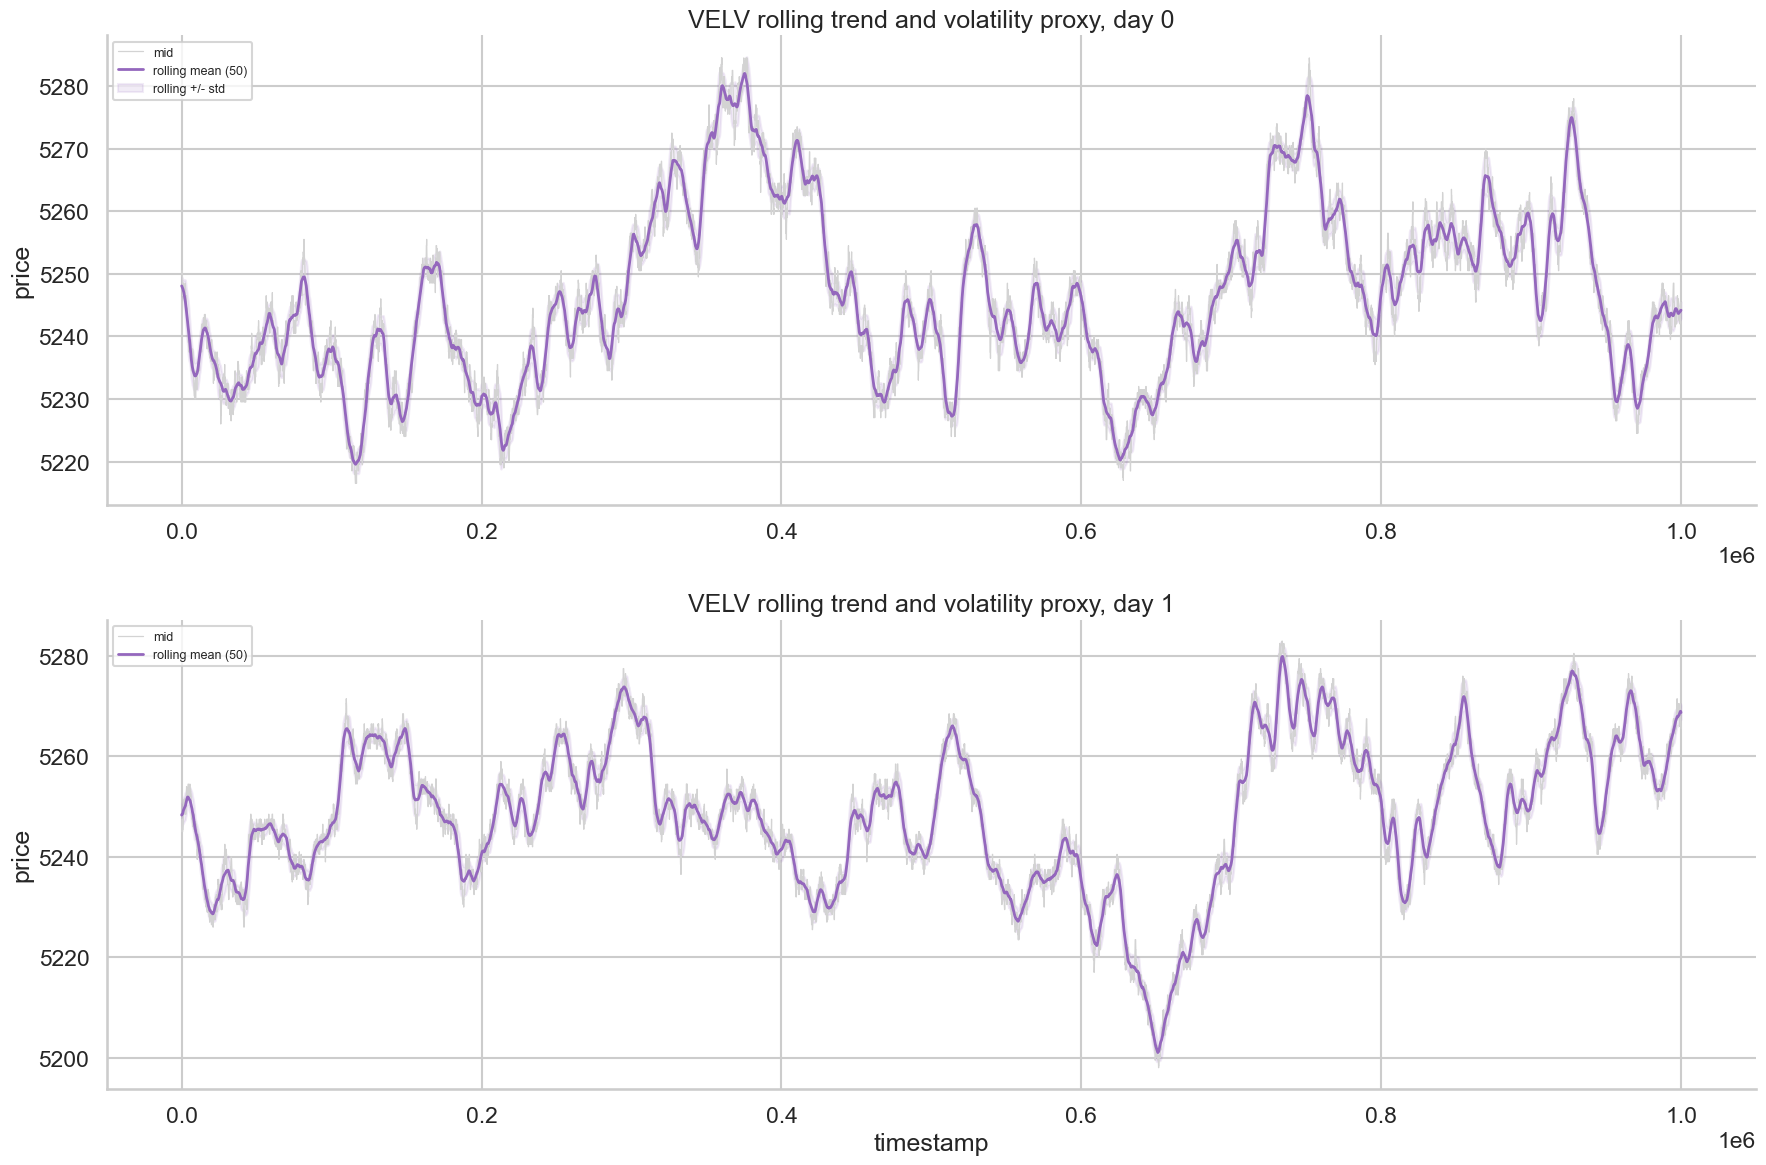

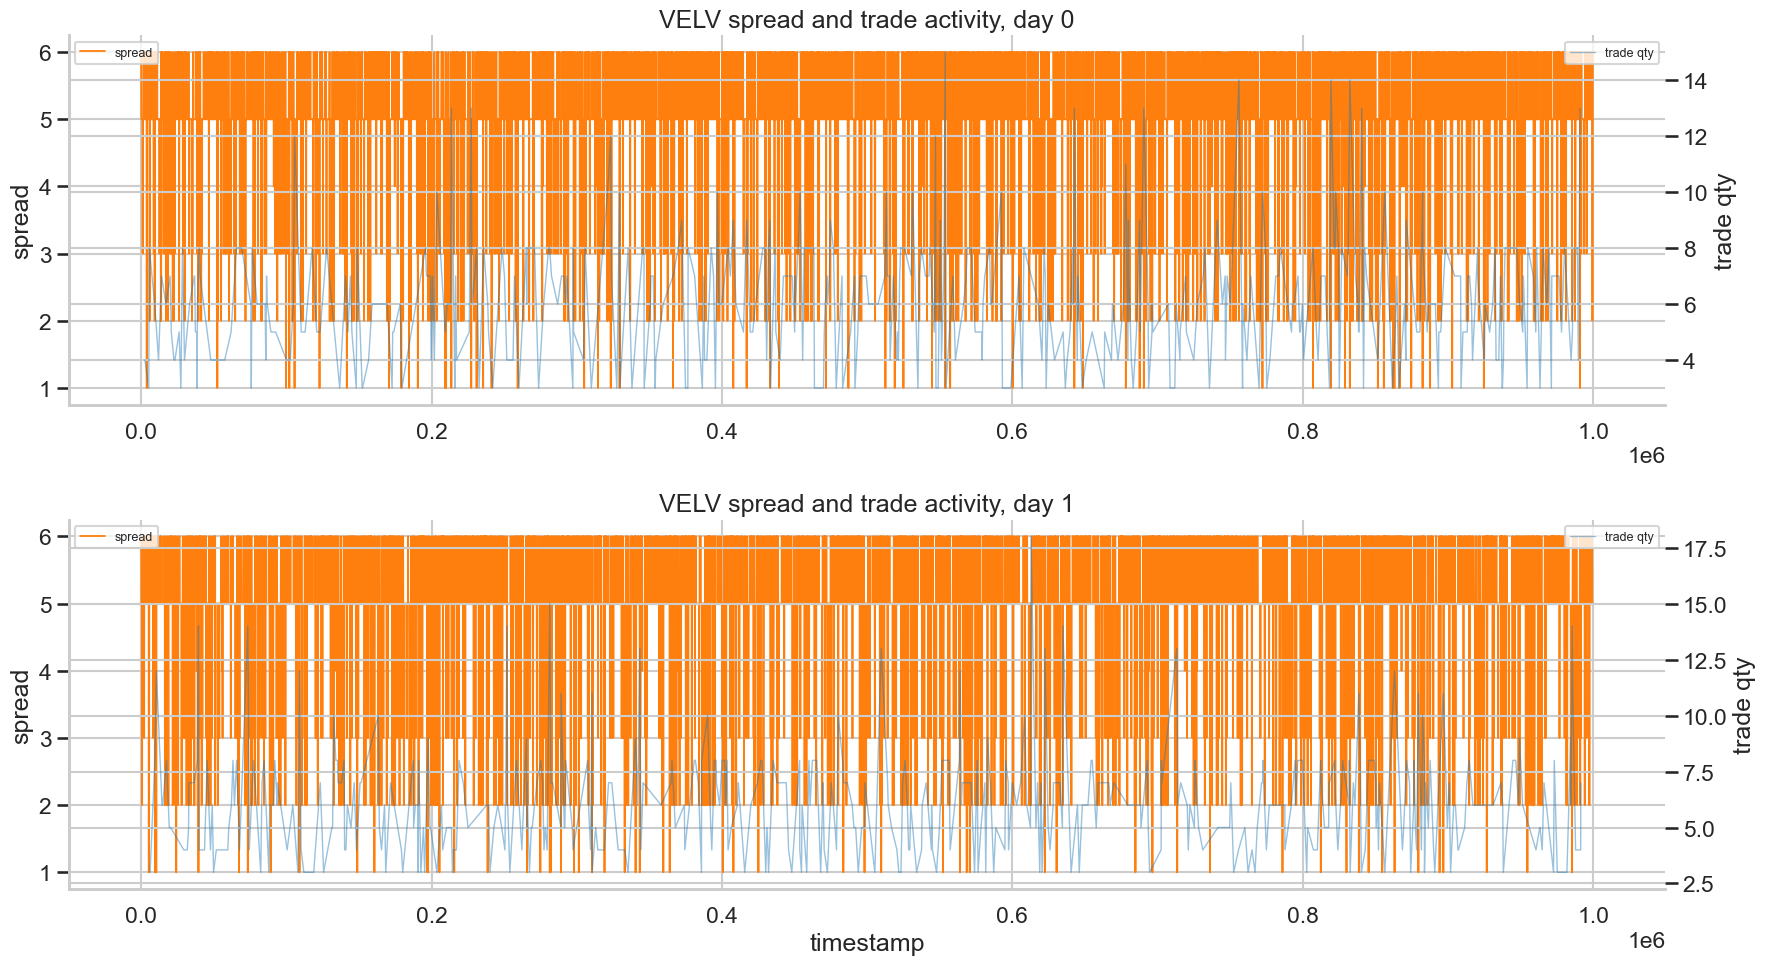

In [4]:
window = 50
fig, axes = plt.subplots(len(days), 1, figsize=(18, 12), sharex=False)

for ax, day in zip(axes, days):
    day_prices = book.loc[book['day'] == day].copy()
    day_prices['rolling_mid'] = day_prices['mid_price'].rolling(window=window, min_periods=10, center=True).mean()
    day_prices['rolling_vol'] = day_prices['mid_price'].rolling(window=window, min_periods=10, center=True).std()

    ax.plot(day_prices['timestamp'], day_prices['mid_price'], color='lightgray', lw=0.9, label='mid')
    ax.plot(day_prices['timestamp'], day_prices['rolling_mid'], color='#9467bd', lw=2.0, label=f'rolling mean ({window})')
    ax.fill_between(
        day_prices['timestamp'],
        day_prices['rolling_mid'] - day_prices['rolling_vol'].fillna(0),
        day_prices['rolling_mid'] + day_prices['rolling_vol'].fillna(0),
        color='#9467bd',
        alpha=0.12,
        label='rolling +/- std' if day == days[0] else None,
    )
    ax.set_title(f'VELV rolling trend and volatility proxy, day {day}')
    ax.set_ylabel('price')
    ax.legend(loc='upper left', fontsize=9)

axes[-1].set_xlabel('timestamp')
plt.tight_layout()

activity = trade_mid.groupby(['day', 'timestamp']).agg(
    trade_qty=('quantity', 'sum'),
    trade_count=('quantity', 'size'),
    notional=('notional', 'sum'),
).reset_index()
activity['vwap'] = activity['notional'] / activity['trade_qty']

fig, axes = plt.subplots(len(days), 1, figsize=(18, 10), sharex=False)
for ax, day in zip(axes, days):
    day_prices = book.loc[book['day'] == day]
    day_activity = activity.loc[activity['day'] == day]
    ax.plot(day_prices['timestamp'], day_prices['spread'], color='#ff7f0e', lw=1.3, label='spread')
    ax2 = ax.twinx()
    ax2.plot(day_activity['timestamp'], day_activity['trade_qty'], color='#1f77b4', lw=1.0, alpha=0.45, label='trade qty')
    ax.set_title(f'VELV spread and trade activity, day {day}')
    ax.set_ylabel('spread')
    ax2.set_ylabel('trade qty')
    ax.legend(loc='upper left', fontsize=9)
    ax2.legend(loc='upper right', fontsize=9)

axes[-1].set_xlabel('timestamp')
plt.tight_layout()

VELV feature table:


,day,observations,mean_mid,std_mid,mean_abs_mid_change,mean_abs_pct_change,zero_mid_change_rate,mean_spread,mean_imbalance
0,0,10000,5246.51025,13.677795,0.847785,0.000162,0.2498,4.9935,0.000694
1,1,10000,5248.39190,14.614362,0.861236,0.000164,0.2443,4.9846,0.001385


VELV lag / price relationship table:


,day,corr_imbalance_next_mid,corr_microprice_mid,corr_spread_abs_change
0,0,0.278068,0.997697,-0.209485
1,1,0.283810,0.998009,-0.224877


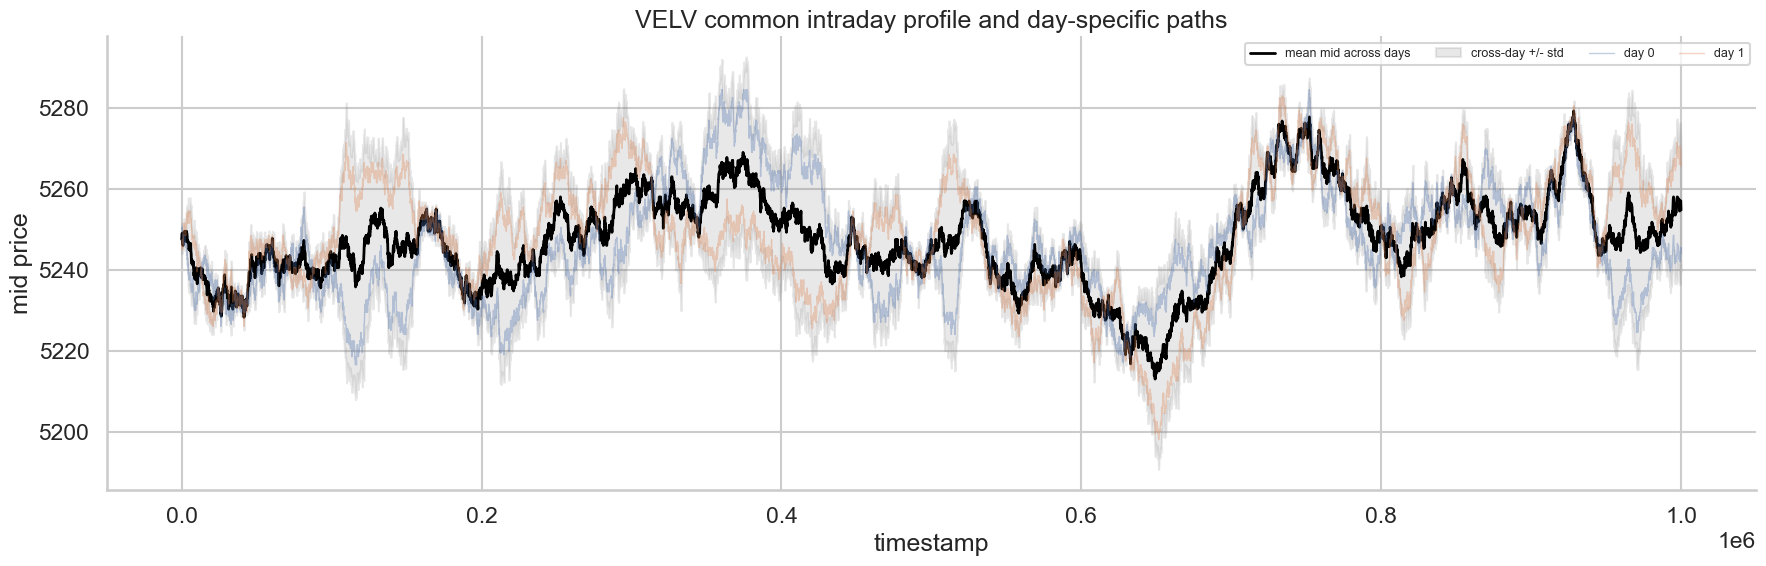

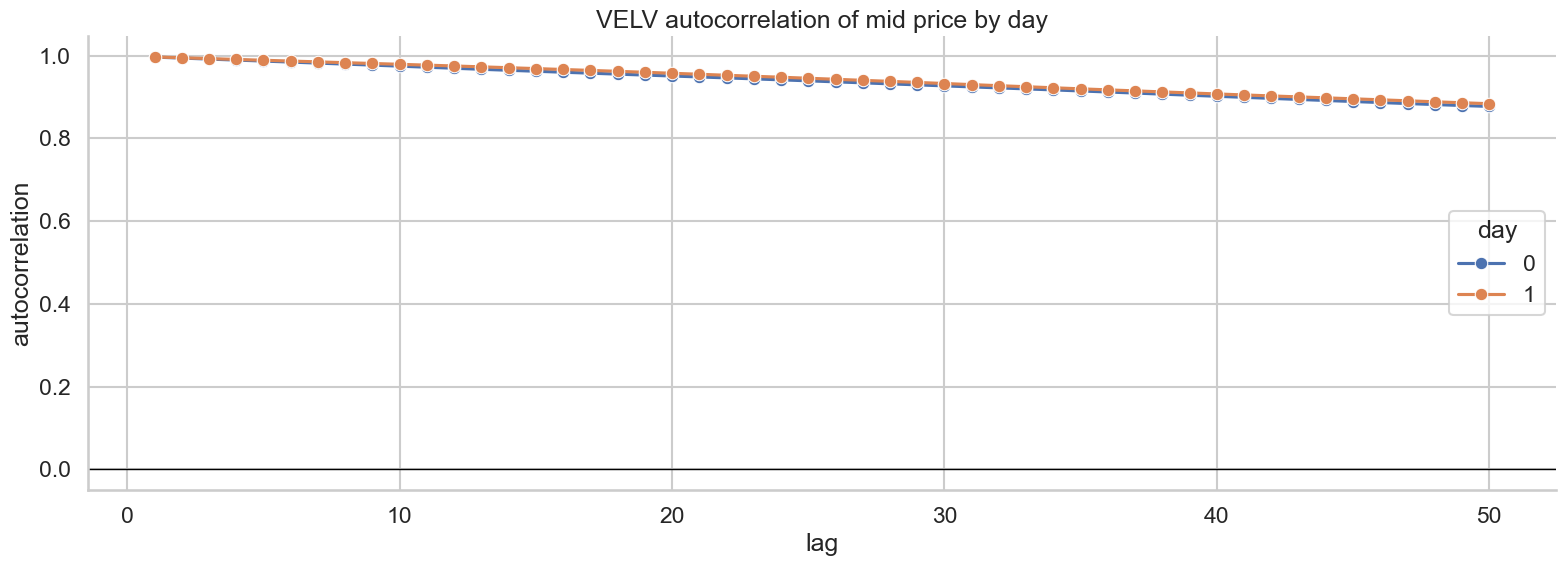

In [5]:
profile = book.groupby('timestamp').agg(
    mean_mid=('mid_price', 'mean'),
    std_mid=('mid_price', 'std'),
    mean_spread=('spread', 'mean'),
).reset_index()
profile['std_mid'] = profile['std_mid'].fillna(0)

fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(profile['timestamp'], profile['mean_mid'], color='black', lw=2, label='mean mid across days')
ax.fill_between(
    profile['timestamp'],
    profile['mean_mid'] - profile['std_mid'],
    profile['mean_mid'] + profile['std_mid'],
    color='gray',
    alpha=0.18,
    label='cross-day +/- std',
)
for day in days:
    day_prices = book.loc[book['day'] == day]
    ax.plot(day_prices['timestamp'], day_prices['mid_price'], alpha=0.35, lw=1.0, label=f'day {day}')
ax.set_title('VELV common intraday profile and day-specific paths')
ax.set_xlabel('timestamp')
ax.set_ylabel('mid price')
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()

lags = range(1, 51)
acf_rows = []
for day, day_prices in book.groupby('day'):
    series = day_prices['mid_price'].reset_index(drop=True)
    acf_rows.extend({'day': day, 'lag': lag, 'autocorr': series.autocorr(lag=lag)} for lag in lags)
acf_df = pd.DataFrame(acf_rows)

fig, ax = plt.subplots(figsize=(16, 6))
sns.lineplot(data=acf_df, x='lag', y='autocorr', hue='day', marker='o', ax=ax)
ax.axhline(0, color='black', lw=1)
ax.set_title('VELV autocorrelation of mid price by day')
ax.set_xlabel('lag')
ax.set_ylabel('autocorrelation')
plt.tight_layout()

feature_table = book.groupby('day').agg(
    observations=('timestamp', 'size'),
    mean_mid=('mid_price', 'mean'),
    std_mid=('mid_price', 'std'),
    mean_abs_mid_change=('mid_change', lambda s: s.abs().mean()),
    mean_abs_pct_change=('pct_change', lambda s: s.abs().mean()),
    zero_mid_change_rate=('mid_change', lambda s: (s == 0).mean()),
    mean_spread=('spread', 'mean'),
    mean_imbalance=('imbalance', 'mean'),
).reset_index()

corr_rows = []
for day, day_prices in book.groupby('day'):
    valid = day_prices[['imbalance', 'next_mid_change', 'microprice', 'mid_price']].dropna()
    corr_rows.append({
        'day': day,
        'corr_imbalance_next_mid': valid['imbalance'].corr(valid['next_mid_change']),
        'corr_microprice_mid': valid['microprice'].corr(valid['mid_price']),
        'corr_spread_abs_change': day_prices['spread'].corr(day_prices['mid_change'].abs()),
    })
corr_table = pd.DataFrame(corr_rows)

print('VELV feature table:')
display(feature_table)
print('VELV lag / price relationship table:')
display(corr_table)

## Notes

- VELV is tighter than PACK and should usually be easier to model as a smoother inventory-style series.
- Keep day 2 out of model selection so the backtest slice stays untouched.
- If the imbalance signal remains stable, this is a cleaner candidate for a simple mean-reversion or microprice-following pass.